 ## **Movie Recommendation Chat Bot Project**
- Models: meta-llama/Llama-3.1-8B-Instruct & Qwen/Qwen3:8b
- Vector DB: ChromaDB
- Data Set: TMDB 5000 (Kaggle) https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata

### **Summary:**
I will be creating a movie recommendation chatbot. I chose twon 8B parameter model because they are big enough to handle the scope but small enough to run quickly on my local machine. I will be using IMDB's data through a vector database and have my model query this via a RAG pipeline to provide the appropriate context. I will use ChromaDB for this. I will also try and create a UI to interface with the model locally likely through streamlit. I want it to be able to conversate, recommend, and compare movies at the users request. It will refrain from answering questions outside of scope with some soft and hard guardrails in place. 

### Merging Movie and Cast Data into one CSV

In [4]:
'''
import pandas as pd

# Load the CSV files into DataFrames
df1 = pd.read_csv('C:\\Users\\Zach\\Downloads\\TMDB_Movie_Data\\tmdb_5000_movies.csv')
df2 = pd.read_csv('C:\\Users\\Zach\\Downloads\\TMDB_Movie_Data\\tmdb_5000_credits.csv')

# Merge side-by-side on a common column
# 'how' options: 'inner' (default), 'left', 'right', or 'outer'
merged_df = pd.merge(df1, df2, left_on='id', right_on='movie_id', how='inner')

# Saved to a new CSV file
merged_df.to_csv('tmdb_5000_merged.csv', index=False) 
'''

### Cleaning JSON formatted column entries

In [ ]:
import pandas as pd
import ast

# 1. Load the TMDB dataset
movieData = pd.read_csv('tmdb_5000_merged.csv')
movieData = movieData.drop(columns=['title_y'])
movieData = movieData.rename(columns={'title_x': 'title'})

# 2. Define a function to extract just the 'name' from the JSON string
def extract_names(json_string):
    try:
        # ast.literal_eval safely parses the stringified list into a real Python list
        parsed_list = ast.literal_eval(json_string)
        
        # Loop through the list of dictionaries and grab only the 'name'
        names = [item['name'] for item in parsed_list]
        
        # Return as a clean, comma-separated string (e.g., "Action, Adventure, Fantasy")
        return ", ".join(names)
    except (ValueError, SyntaxError):
        # Return an empty string if the data is missing or corrupted
        return ""

# 3. Apply the function to the messy columns
movieData['clean_genres'] = movieData['genres'].apply(extract_names)
movieData['clean_keywords'] = movieData['keywords'].apply(extract_names)
movieData['clean_production_companies'] = movieData['production_companies'].apply(extract_names)
movieData['clean_production_countries'] = movieData['production_countries'].apply(extract_names)
movieData['clean_spoken_languages'] = movieData['spoken_languages'].apply(extract_names)
movieData['clean_cast'] = movieData['cast'].apply(extract_names)
movieData['clean_crew'] = movieData['crew'].apply(extract_names)


# For the cast, you might only want the top 5 actors so you don't bloat the database
def extract_top_5_cast(json_string):
    try:
        parsed_list = ast.literal_eval(json_string)
        # Slice the list to grab only the first 5 items
        names = [item['name'] for item in parsed_list[:5]]
        return ", ".join(names)
    except (ValueError, SyntaxError):
        return ""

movieData['clean_cast'] = movieData['cast'].apply(extract_top_5_cast)

# Cleaning crew to only include Directors, Writers, and Producers
def extract_important_crew(json_string):
    # These sets define which exact TMDB jobs belong under each label.
    role_jobs = {
        "Director": {"Director", "Co-Director"},
        "Writer": {
            "Writer",
            "Screenplay",
            "Co-Writer",
            "Additional Writing",
            "Scenario Writer",
        },
        "Producer": {
            "Producer",
            "Co-Producer",
            "Executive Producer",
            "Co-Executive Producer",
            "Line Producer",
            "Supervising Producer",
        },
    }

    try:
        crew_list = ast.literal_eval(json_string)
    except (ValueError, SyntaxError, TypeError):
        return ""

    if not isinstance(crew_list, list):
        return ""

    results = []

    # Iterating through role_jobs sets the output order, regardless of crew order.
    for role, jobs in role_jobs.items():
        names = list(dict.fromkeys(
            person.get("name")
            for person in crew_list
            if isinstance(person, dict)
            and person.get("job") in jobs
            and person.get("name")
        ))

        if names:
            results.append(f"{role}: {', '.join(names)}")

    return "; ".join(results)


movieData["clean_crew"] = movieData["crew"].apply(extract_important_crew)

print(movieData.iloc[0]) 

budget                                                                237000000
genres                        [{"id": 28, "name": "Action"}, {"id": 12, "nam...
homepage                                            http://www.avatarmovie.com/
id                                                                        19995
keywords                      [{"id": 1463, "name": "culture clash"}, {"id":...
original_language                                                            en
original_title                                                           Avatar
overview                      In the 22nd century, a paraplegic Marine is di...
popularity                                                           150.437577
production_companies          [{"name": "Ingenious Film Partners", "id": 289...
production_countries          [{"iso_3166_1": "US", "name": "United States o...
release_date                                                         2009-12-10
revenue                                 

In [ ]:
# Now we format for ChromaDB (our vector database)
import math

documents = []
metadatas = []
ids = []

for index, row in movieData.iterrows():
    # 1. Extract and Build the Text Document
    try:
        release_year = int(str(row['release_date']).split('-')[0])
    except (ValueError, AttributeError):
        release_year = 0  # Fallback if date is missing
            
    # Check for NaN in numerical columns
    rating = float(row['vote_average']) if not math.isnan(row['vote_average']) else 0.0
    popularity = float(row['popularity']) if not math.isnan(row['popularity']) else 0.0
    runtime = float(row['runtime']) if not math.isnan(row['runtime']) else 0.0
    
    rich_text = (
        f"Title: {row['title']}. "
        f"Release Year: {release_year}. "
        f"Rating: {rating}/10. "
        f"Cast: {row['clean_cast']}. "
        f"Genres: {row['clean_genres']}. "
        f"Keywords: {row['clean_keywords']}. "
        f"Plot summary: {row['overview']}"
    )
    
    # 2. Extract and Validate Metadata
    # Convert string dates to integer years (e.g., "2009-12-10" -> 2009)
    metadata = {
        "rating": rating,             # Float
        "popularity": popularity,     # Float
        "runtime": runtime,           # Float
        "release_year": release_year, # Integer
        "title": str(row['title'])    # String (Useful to return the title instantly without parsing the text block)
    }
    
    # 3. Append to lists
    documents.append(rich_text)
    metadatas.append(metadata)
    ids.append(f"movie_{row['id']}")  # Using the actual TMDB ID for precision

# Each movie should produce exactly one document, metadata dictionary, and ID.
expected_count = len(movieData)
assert len(documents) == expected_count
assert len(metadatas) == expected_count
assert len(ids) == expected_count

# IDs should match the movie rows in the same order.
expected_ids = [f"movie_{movie_id}" for movie_id in movieData["id"]]
assert ids == expected_ids
assert len(set(ids)) == len(ids), "Movie IDs are not unique"

# Check that each metadata dictionary has the fields you expect.
required_metadata = {"rating", "popularity", "runtime", "release_year", "title"}
assert all(required_metadata.issubset(metadata) for metadata in metadatas)

print(f"Validated {expected_count} documents, metadata dictionaries, and IDs.")

Validated 4803 documents, metadata dictionaries, and IDs.


In [5]:
# Ensuring formats are correct for the vector database
preview = pd.DataFrame({
    "id": ids,
    "metadata": metadatas,
    "document": documents,
})

display(preview.sample(n=min(5, len(preview)), random_state=42))

,id,metadata,document
596,movie_8427,"{'rating': 5.2, 'popularity': 13.267631, 'runt...",Title: I Spy. Release Year: 2002. Rating: 5.2/...
3372,movie_13006,"{'rating': 5.7, 'popularity': 4.857028, 'runti...",Title: Split Second. Release Year: 1992. Ratin...
2702,movie_18041,"{'rating': 5.5, 'popularity': 5.833687, 'runti...",Title: Gossip. Release Year: 2000. Rating: 5.5...
2473,movie_5038,"{'rating': 6.7, 'popularity': 32.758254, 'runt...",Title: Vicky Cristina Barcelona. Release Year:...
8,movie_767,"{'rating': 7.4, 'popularity': 98.885637, 'runt...",Title: Harry Potter and the Half-Blood Prince....


## Vector Database Data Transfer
*Now That we have cleaned our data and formatted it for the way ChromaDB requires it, we will insert in batches of 1000*

In [ ]:
import chromadb
from chromadb.utils.embedding_functions.ollama_embedding_function import OllamaEmbeddingFunction

# 1. Initialize the ChromaDB Client (The storage engine)
client = chromadb.PersistentClient(path="./movie_vector_db") 

# 2. Set up the Embedding Function via Ollama
ollama_ef = OllamaEmbeddingFunction(
    url="http://localhost:11434",
    model_name="nomic-embed-text"
)

# 3. Define the Collection
collection = client.get_or_create_collection(
    name="movies",
    embedding_function=ollama_ef,
    metadata={"hnsw:space": "cosine"}
)

batch_size = 100

for i in range(0, len(documents), batch_size):
    # Slice the arrays
    batch_docs = documents[i : i + batch_size]
    batch_metas = metadatas[i : i + batch_size]
    batch_ids = ids[i : i + batch_size]
    
    # Add the batch
    collection.add(
        documents=batch_docs,
        metadatas=batch_metas,
        ids=batch_ids
    )
    print(f"Inserted batch {i // batch_size + 1}...")

print("All movies successfully added to ChromaDB!")

Inserted batch 1...
Inserted batch 2...
Inserted batch 3...
Inserted batch 4...
Inserted batch 5...
Inserted batch 6...
Inserted batch 7...
Inserted batch 8...
Inserted batch 9...
Inserted batch 10...
Inserted batch 11...
Inserted batch 12...
Inserted batch 13...
Inserted batch 14...
Inserted batch 15...
Inserted batch 16...
Inserted batch 17...
Inserted batch 18...
Inserted batch 19...
Inserted batch 20...
Inserted batch 21...
Inserted batch 22...
Inserted batch 23...
Inserted batch 24...
Inserted batch 25...
Inserted batch 26...
Inserted batch 27...
Inserted batch 28...
Inserted batch 29...
Inserted batch 30...
Inserted batch 31...
Inserted batch 32...
Inserted batch 33...
Inserted batch 34...
Inserted batch 35...
Inserted batch 36...
Inserted batch 37...
Inserted batch 38...
Inserted batch 39...
Inserted batch 40...
Inserted batch 41...
Inserted batch 42...
Inserted batch 43...
Inserted batch 44...
Inserted batch 45...
Inserted batch 46...
Inserted batch 47...
Inserted batch 48...
I

: 

## Running the model:
Now that we have inserted all the movies into ChromaDB, we write our app.py file that configures our agent, its connection to the DB, how it handles context, its system prompt etc. 

#### In the terminal run *python -m streamlit run app.py* to acess the model UI/ app!

### SQLite DB for Agent Telemetry

In [8]:
from pathlib import Path
import sqlite3
import pandas as pd

db_path = Path("telemetry.sqlite3").resolve()
print("Database path:", db_path)
print("Exists:", db_path.exists())

with sqlite3.connect(db_path) as conn:
    calls = pd.read_sql_query(
        "SELECT * FROM model_calls ORDER BY created_at DESC",
        conn,
    )

calls.head()

Database path: C:\Users\Zach\Movie Rec Chat Bot Project\telemetry.sqlite3
Exists: True


,id,created_at,model,call_type,wall_ms,total_duration_ns,prompt_tokens,output_tokens,prompt_eval_duration_ns,eval_duration_ns,tokens_per_second,time_to_first_token_ms,gpu_temp_c,gpu_utilization_pct,gpu_metrics_status,error,success
0,33,2026-10-29T17:44:55.778308+00:00,qwen3:8b,answer_generation,56478.3452,56473563500,3744,1204,9695938000,46638377000,25.815650,33829.7103,83.0,100.0,available,None,1
1,32,2026-10-29T17:43:57.217955+00:00,qwen3:8b,query_rewrite,13152.2365,13149457100,1322,254,3278885000,9648029000,26.326621,12808.2997,78.0,99.0,available,None,1
2,31,2026-10-29T17:43:23.366272+00:00,qwen3:8b,answer_generation,56803.5349,56798937700,2943,1266,7305862000,49315893000,25.671237,31253.5399,83.0,100.0,available,None,1
3,30,2026-10-29T17:42:24.490481+00:00,qwen3:8b,query_rewrite,37636.3310,37633263900,1312,889,3280941000,34044828999,26.112629,37321.4388,82.0,99.0,available,None,1
4,29,2026-10-29T17:41:30.982438+00:00,qwen3:8b,answer_generation,41973.9429,41958715000,2716,916,6741770000,35092696000,26.102298,20336.9500,82.0,100.0,available,None,1


In [ ]:
#Comparison Query for Model Performance

query = """
SELECT
    model,
    COUNT(*) AS call_count,
    ROUND(AVG(wall_ms) / 1000.0, 2) AS avg_wall_s,
    ROUND(AVG(prompt_tokens), 1) AS avg_prompt_tokens,
    ROUND(AVG(output_tokens), 1) AS avg_output_tokens,
    ROUND(AVG(prompt_eval_duration_ns) / 1000000000.0, 2)
        AS avg_prompt_eval_s,
    ROUND(AVG(tokens_per_second), 2) AS avg_tokens_per_second,
    ROUND(AVG(time_to_first_token_ms) / 1000.0, 2)
        AS avg_time_to_first_token_s,
    ROUND(AVG(gpu_temp_c), 1) AS avg_gpu_temp_c,
    ROUND(AVG(gpu_utilization_pct), 1) AS avg_gpu_utilization_pct,
    ROUND(100.0 * AVG(success), 1) AS success_pct,
    SUM(CASE WHEN success = 0 THEN 1 ELSE 0 END) AS failed_calls
FROM model_calls
WHERE model IN ('llama3.1:8b', 'qwen3:8b')
GROUP BY model
ORDER BY model
"""

with sqlite3.connect(db_path) as conn:
    averages = pd.read_sql_query(query, conn)

averages

,model,call_count,avg_wall_s,avg_prompt_tokens,avg_output_tokens,avg_prompt_eval_s,avg_tokens_per_second,avg_time_to_first_token_s,avg_gpu_temp_c,avg_gpu_utilization_pct,success_pct,failed_calls
0,llama3.1:8b,22,8.03,1481.1,111.6,2.59,30.98,4.29,59.8,100.0,100.0,0
1,qwen3:8b,11,38.70,1709.5,885.7,4.19,26.42,28.43,77.8,99.4,100.0,0


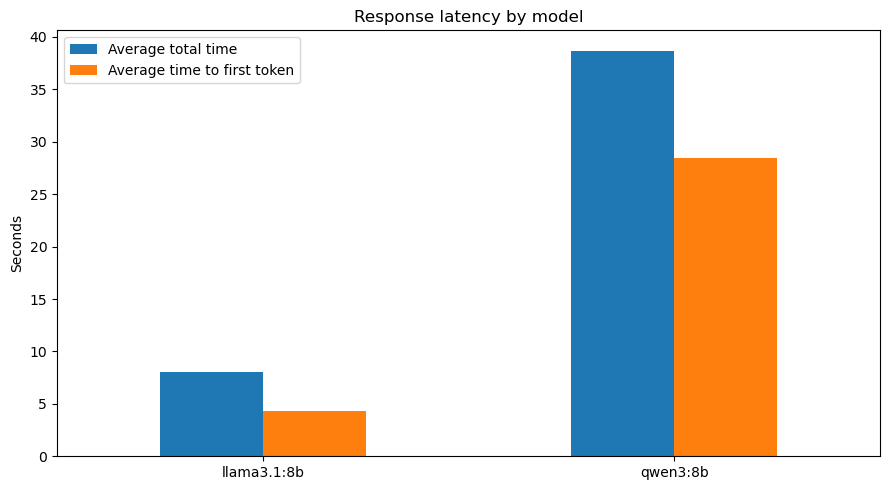

In [ ]:
#Visual 1 - response latency by model

import matplotlib.pyplot as plt

chart_data = averages.set_index("model")[
    ["avg_wall_s", "avg_time_to_first_token_s"]
]

ax = chart_data.plot(kind="bar", figsize=(9, 5), rot=0)
ax.set_title("Response latency by model")
ax.set_xlabel("")
ax.set_ylabel("Seconds")
ax.legend(["Average total time", "Average time to first token"])
plt.tight_layout()
plt.show()

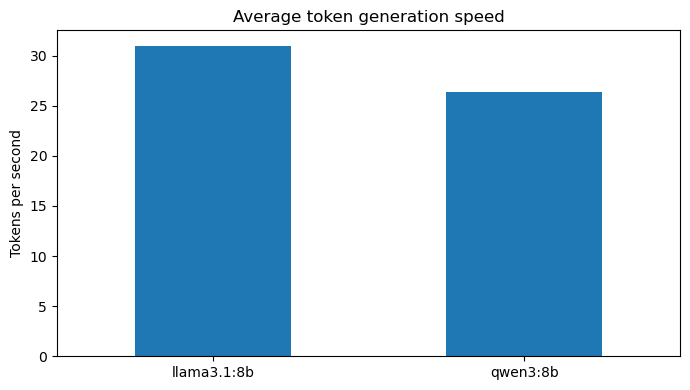

In [ ]:
#Visual 2 - token gen speed

ax = averages.set_index("model")["avg_tokens_per_second"].plot(
    kind="bar", figsize=(7, 4), rot=0
)
ax.set_title("Average token generation speed")
ax.set_xlabel("")
ax.set_ylabel("Tokens per second")
plt.tight_layout()
plt.show()